# Fruit Ripeness Grading via Ordinal Regression — ResNet152

## Dataset-ready classification notebook

This notebook is configured specifically for **banana ripeness classification** using the Mendeley **BananaID** dataset. The dataset contains four ordered ripeness stages: **Unripe → Half-ripe → Ripe → Overripe**, with 1,960 original ripeness images. The dataset is designed for image classification and provides a natural ordinal target.

The experiment compares:

1. **Standard multiclass classification** using softmax + categorical cross-entropy.
2. **Ordinal regression** using cumulative threshold outputs and an ordinal binary cross-entropy loss.

Both models use the same **ResNet152 architecture, image preprocessing, train/validation/test split, and training budget** so that the comparison is meaningful.

Dataset source: Mendeley Data, *BananaID: An image dataset of banana varieties and ripeness stages in Indonesia designed for classification*.


## Expected dataset structure

Download the **original ripeness-classification images** from the BananaID dataset and place them under `./dataset`.

The loader below is flexible and searches recursively, so the exact nesting does not matter as long as folders can be identified by these class names:

```text
dataset/
├── Unripe/
├── Half-ripe/
├── Ripe/
└── Overripe/
```

It also accepts lowercase or common naming variants such as `half_ripe`, `half-ripe`, `over_ripe`, etc.

**Important:** use the original images rather than the augmented images. Augmentation is performed inside the training pipeline to avoid evaluation leakage.


In [1]:
import os
import zipfile

zip_path = "/content/Banana Ripeness Dataset.zip"

print("File exists:", os.path.exists(zip_path))
print("File size:", os.path.getsize(zip_path) / (1024 * 1024), "MB")
print("Valid ZIP:", zipfile.is_zipfile(zip_path))

with open(zip_path, "rb") as f:
    print("First bytes:", f.read(20))

File exists: True
File size: 24.794018745422363 MB
Valid ZIP: True
First bytes: b'PK\x03\x04\x14\x00\x00\x00\x00\x00(\xb0o[\x00\x00\x00\x00\x00\x00'


In [2]:
import zipfile
import os

zip_path = "/content/Banana Ripeness Dataset.zip"
extract_path = "/content/dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [3]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    mean_absolute_error,
    classification_report,
    confusion_matrix
)

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 40
LEARNING_RATE = 1e-4

CLASS_NAMES = ["unripe", "half-ripe", "ripe", "overripe"]
NUM_CLASSES = len(CLASS_NAMES)
DATASET_DIR = Path("./dataset")
MODEL_DIR = Path("./saved_models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Dataset directory:", DATASET_DIR.resolve())


TensorFlow: 2.21.0
Dataset directory: /content/dataset


In [4]:
import os

for root, dirs, files in os.walk("/content/dataset"):
    print(root, "->", len(files), "files")

/content/dataset -> 0 files
/content/dataset/Banana Ripeness Classification Dataset -> 0 files
/content/dataset/Banana Ripeness Classification Dataset/Overripe -> 448 files
/content/dataset/Banana Ripeness Classification Dataset/Half_Ripe -> 488 files
/content/dataset/Banana Ripeness Classification Dataset/Unripe -> 408 files
/content/dataset/Banana Ripeness Classification Dataset/Ripe -> 616 files


## 1. Find and inspect the images

The following code recursively searches the dataset directory and maps folder names to the four ordered ripeness labels.


In [5]:
from pathlib import Path
import pandas as pd

DATASET_DIR = Path("/content/dataset")

CLASS_ALIASES = {
    "unripe": 0,
    "green": 0,
    "half_ripe": 1,
    "half-ripe": 1,
    "half ripe": 1,
    "ripe": 2,
    "overripe": 3,
    "over-ripe": 3,
    "over_ripe": 3,
    "over ripe": 3
}

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def normalize_folder_name(name):
    return name.lower().strip().replace("-", "_").replace(" ", "_")

def label_from_folder(folder_name):
    key = normalize_folder_name(folder_name)
    return CLASS_ALIASES.get(key)

records = []

for path in DATASET_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
        label = label_from_folder(path.parent.name)

        if label is not None:
            records.append({
                "filepath": str(path),
                "label": label,
                "class_name": CLASS_NAMES[label]
            })

df = pd.DataFrame(records)

print("Dataset path:", DATASET_DIR)
print("Total images found:", len(df))

if df.empty:
    print("\nNo images were detected.")
    print("\nFolders found inside /content/dataset:")

    for path in DATASET_DIR.rglob("*"):
        if path.is_dir():
            print(path)

    raise FileNotFoundError(
        "No labelled images were found. Check the folder structure shown above."
    )

display(df.head())

print("\nClass distribution:")

display(
    df["class_name"]
    .value_counts()
    .reindex(CLASS_NAMES)
    .fillna(0)
    .astype(int)
)

Dataset path: /content/dataset
Total images found: 1960


,filepath,label,class_name
0,/content/dataset/Banana Ripeness Classificatio...,3,overripe
1,/content/dataset/Banana Ripeness Classificatio...,3,overripe
2,/content/dataset/Banana Ripeness Classificatio...,3,overripe
3,/content/dataset/Banana Ripeness Classificatio...,3,overripe
4,/content/dataset/Banana Ripeness Classificatio...,3,overripe



Class distribution:


,count
class_name,
unripe,408
half-ripe,488
ripe,616
overripe,448


## 2. Visualize the dataset distribution


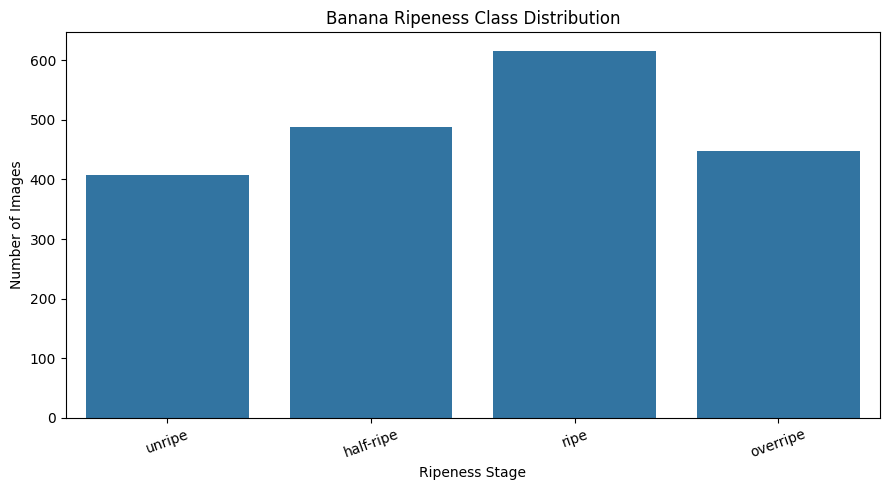

In [6]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="class_name", order=CLASS_NAMES)
plt.title("Banana Ripeness Class Distribution")
plt.xlabel("Ripeness Stage")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 3. Stratified train/validation/test split

The split is **70% training, 15% validation, and 15% test**. Stratification preserves the relative frequency of each ripeness class.

The split is performed before augmentation, so validation and test images remain untouched.


In [7]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

split_summary = pd.DataFrame({
    "train": train_df["class_name"].value_counts(),
    "validation": val_df["class_name"].value_counts(),
    "test": test_df["class_name"].value_counts()
}).reindex(CLASS_NAMES).fillna(0).astype(int)

display(split_summary)


Train: 1372
Validation: 294
Test: 294


,train,validation,test
class_name,,,
unripe,286,61,61
half-ripe,341,73,74
ripe,431,93,92
overripe,314,67,67


## 4. Class weights

Class weights are calculated from the training set. They are used for the standard classifier. The ordinal model uses the same training images but its threshold targets are handled directly by the ordinal loss.


In [8]:
classes = np.arange(NUM_CLASSES)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"].values
)
class_weights = dict(zip(classes, weights))
class_weights


{np.int64(0): np.float64(1.1993006993006994),
 np.int64(1): np.float64(1.0058651026392962),
 np.int64(2): np.float64(0.7958236658932715),
 np.int64(3): np.float64(1.0923566878980893)}

## 5. TensorFlow input pipeline

Images are resized to **224 × 224**, converted to RGB, and scaled to the range expected by the Keras ResNet152 preprocessing function.

Augmentation is applied only to training batches.


In [9]:
from tensorflow.keras.applications.resnet import preprocess_input

AUTOTUNE = tf.data.AUTOTUNE

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="data_augmentation")

def load_image(path):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image

def make_dataset(frame, target_mode="categorical", training=False):
    paths = frame["filepath"].values
    labels = frame["label"].values.astype(np.int32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=len(frame),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    def mapper(path, label):
        image = load_image(path)
        if training:
            image = data_augmentation(image, training=True)
        image = preprocess_input(image)

        if target_mode == "categorical":
            return image, label
        else:
            ordinal_target = tf.cast(
                tf.range(NUM_CLASSES - 1) < label,
                tf.float32
            )
            return image, ordinal_target

    ds = ds.map(mapper, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds_cat = make_dataset(train_df, "categorical", True)
val_ds_cat = make_dataset(val_df, "categorical", False)
test_ds_cat = make_dataset(test_df, "categorical", False)

train_ds_ord = make_dataset(train_df, "ordinal", True)
val_ds_ord = make_dataset(val_df, "ordinal", False)
test_ds_ord = make_dataset(test_df, "ordinal", False)


# Part A — Standard multiclass classification

The baseline predicts one of four classes with a softmax output:

`[Unripe, Half-ripe, Ripe, Overripe]`.


In [10]:
def build_resnet152_backbone():
    return keras.applications.ResNet152(
        include_top=False,
        weights=None,
        input_shape=(*IMG_SIZE, 3)
    )

def build_categorical_model():
    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    backbone = build_resnet152_backbone()
    x = backbone(inputs, training=True)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="ResNet152_Categorical")

categorical_model = build_categorical_model()

categorical_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

categorical_model.summary()


Model: "ResNet152_Categorical"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet152 (Functional)          │ (None, 7, 7, 2048)     │    58,370,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,896,516 (224.67 MB)

 Trainable params: 58,745,092 (224.09 MB)

 Non-trainable params: 151,424 (591.50 KB)

In [11]:
categorical_callbacks = [
    keras.callbacks.ModelCheckpoint(
        MODEL_DIR / "resnet152_categorical_best.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max"
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="accuracy",
        mode="max",
        patience=6,
        restore_best_weights=True
    )
]

history_cat = categorical_model.fit(
    train_ds_cat,
    validation_data=val_ds_cat,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=categorical_callbacks
)


Epoch 1/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 301s 2s/step - accuracy: 0.3258 - loss: 1.6978 - val_accuracy: 0.2483 - val_loss: 1.5011 - learning_rate: 1.0000e-04
Epoch 2/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 53s 617ms/step - accuracy: 0.3834 - loss: 1.2959 - val_accuracy: 0.2483 - val_loss: 2.0099 - learning_rate: 1.0000e-04
Epoch 3/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 55s 636ms/step - accuracy: 0.5233 - loss: 1.0283 - val_accuracy: 0.2483 - val_loss: 2.1944 - learning_rate: 1.0000e-04
Epoch 4/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 597ms/step - accuracy: 0.5577 - loss: 1.0020
Epoch 4: ReduceLROnPlateau reducing learning rate to 1.9999999494757503e-05.
86/86 ━━━━━━━━━━━━━━━━━━━━ 75s 874ms/step - accuracy: 0.5729 - loss: 0.9626 - val_accuracy: 0.4558 - val_loss: 1.6622 - learning_rate: 1.0000e-04
Epoch 5/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 112s 1s/step - accuracy: 0.6312 - loss: 0.8402 - val_accuracy: 0.5374 - val_loss: 1.0812 - learning_rate: 2.0000e-05
Epoch 6/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 72s 833ms/step - accuracy: 0.

## Categorical learning curves


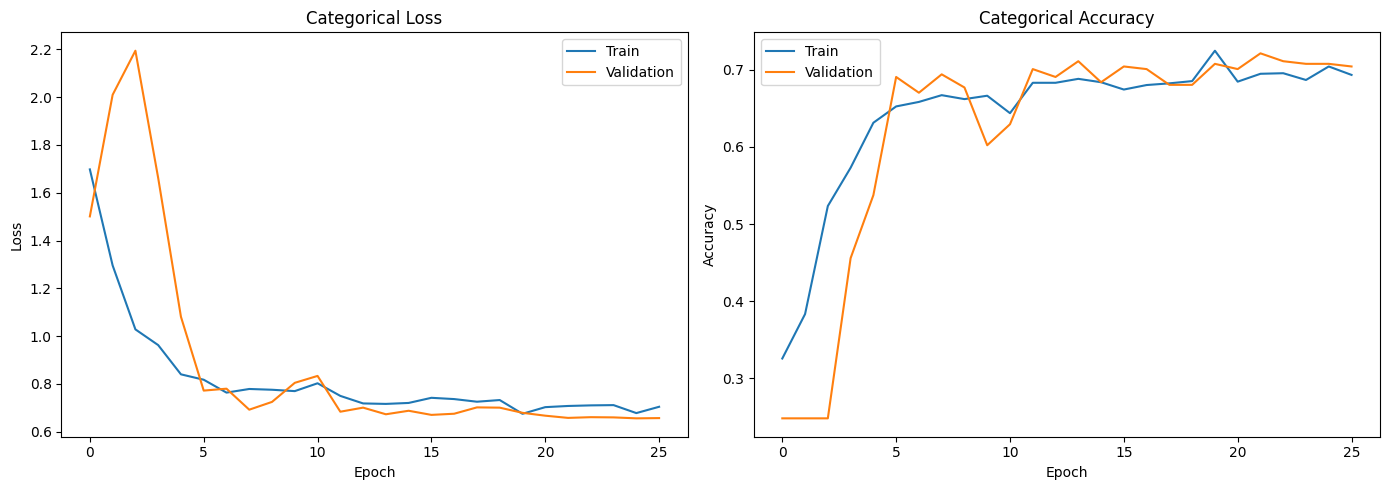

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(history_cat.history["loss"], label="Train")
ax[0].plot(history_cat.history["val_loss"], label="Validation")
ax[0].set_title("Categorical Loss")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss")
ax[0].legend()

ax[1].plot(history_cat.history["accuracy"], label="Train")
ax[1].plot(history_cat.history["val_accuracy"], label="Validation")
ax[1].set_title("Categorical Accuracy")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy")
ax[1].legend()

plt.tight_layout()
plt.show()


## Evaluate the categorical classifier


19/19 ━━━━━━━━━━━━━━━━━━━━ 22s 645ms/step
Categorical Accuracy: 0.6973
Categorical MAE: 0.3333

Classification Report:
              precision    recall  f1-score   support

      unripe     0.7500    0.8852    0.8120        61
   half-ripe     0.6190    0.5270    0.5693        74
        ripe     0.6842    0.7065    0.6952        92
    overripe     0.7344    0.7015    0.7176        67

    accuracy                         0.6973       294
   macro avg     0.6969    0.7051    0.6985       294
weighted avg     0.6929    0.6973    0.6929       294



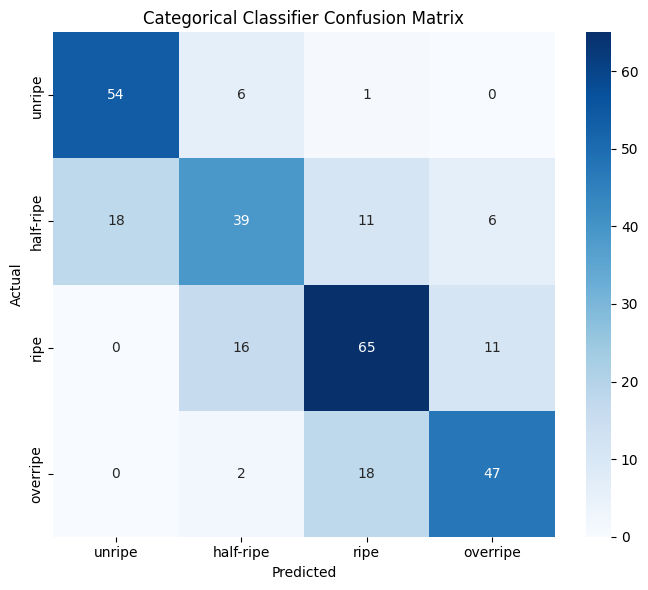

In [13]:
cat_prob = categorical_model.predict(test_ds_cat)
cat_pred = np.argmax(cat_prob, axis=1)
cat_true = test_df["label"].values

cat_accuracy = accuracy_score(cat_true, cat_pred)
cat_mae = mean_absolute_error(cat_true, cat_pred)

print(f"Categorical Accuracy: {cat_accuracy:.4f}")
print(f"Categorical MAE: {cat_mae:.4f}")

print("\nClassification Report:")
print(classification_report(
    cat_true,
    cat_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

plt.figure(figsize=(7, 6))
sns.heatmap(
    confusion_matrix(cat_true, cat_pred, labels=np.arange(NUM_CLASSES)),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.title("Categorical Classifier Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


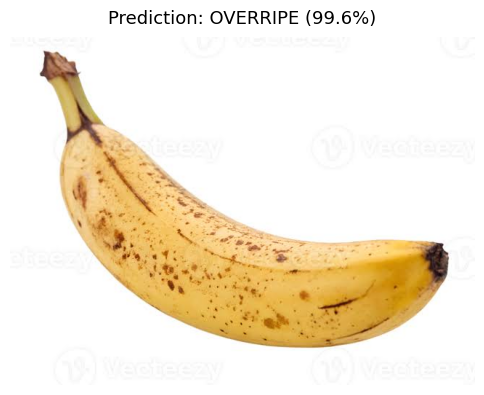

IMAGE: image.jpg
--- Categorical Softmax Probabilities ---
  Unripe      :   0.04%
  Half-ripe   :   0.04%
  Ripe        :   0.33%
  Overripe    :  99.59%
  --> Final Prediction: Overripe


In [16]:
def predict_single_image(image_path):
    # 1. Load and display image
    raw_img = Image.open(image_path).convert('RGB')

    # 2. Preprocess (224x224, ResNet preprocess_input)
    img_resized = raw_img.resize(IMG_SIZE)
    img_array = np.array(img_resized, dtype=np.float32)
    img_preprocessed = preprocess_input(img_array)
    img_batch = np.expand_dims(img_preprocessed, axis=0)

    # 3. Categorical Model Prediction
    cat_probs = categorical_model.predict(img_batch, verbose=0)[0]
    cat_pred_idx = np.argmax(cat_probs)
    cat_class = CLASS_NAMES[cat_pred_idx]

    # 4. Display visualization and outputs
    plt.figure(figsize=(6, 6))
    plt.imshow(raw_img)
    plt.axis("off")
    plt.title(f"Prediction: {cat_class.upper()} ({cat_probs[cat_pred_idx]*100:.1f}%)", fontsize=13, pad=10)
    plt.show()

    print("=" * 45)
    print(f"IMAGE: {image_path}")
    print("=" * 45)
    print("--- Categorical Softmax Probabilities ---")
    for name, p in zip(CLASS_NAMES, cat_probs):
        print(f"  {name.capitalize():<12}: {p * 100:6.2f}%")
    print(f"  --> Final Prediction: {cat_class.capitalize()}")
    print("=" * 45)

# Test with your already-uploaded file
predict_single_image("image.jpg")

# Part B — Ordinal regression

Ripeness is ordered:

**Unripe < Half-ripe < Ripe < Overripe**

Instead of treating the four classes as unrelated categories, ordinal regression learns three cumulative thresholds:

- `P(y > Unripe)`
- `P(y > Half-ripe)`
- `P(y > Ripe)`

The target encodings are:

- Unripe → `[0, 0, 0]`
- Half-ripe → `[1, 0, 0]`
- Ripe → `[1, 1, 0]`
- Overripe → `[1, 1, 1]`


In [17]:
def ordinal_bce_loss(y_true, y_pred):
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
    loss = -(
        y_true * tf.math.log(y_pred) +
        (1.0 - y_true) * tf.math.log(1.0 - y_pred)
    )
    return tf.reduce_mean(loss)

def build_ordinal_model():
    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    backbone = build_resnet152_backbone()
    x = backbone(inputs, training=True)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(NUM_CLASSES - 1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name="ResNet152_Ordinal")

ordinal_model = build_ordinal_model()

ordinal_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=ordinal_bce_loss
)

ordinal_model.summary()


Model: "ResNet152_Ordinal"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet152 (Functional)          │ (None, 7, 7, 2048)     │    58,370,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,896,259 (224.67 MB)

 Trainable params: 58,744,835 (224.09 MB)

 Non-trainable params: 151,424 (591.50 KB)

In [18]:
ordinal_callbacks = [
    keras.callbacks.ModelCheckpoint(
        MODEL_DIR / "resnet152_ordinal_best.keras",
        monitor="val_loss",
        save_best_only=True,
        mode="min"
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True
    )
]

history_ord = ordinal_model.fit(
    train_ds_ord,
    validation_data=val_ds_ord,
    epochs=EPOCHS,
    callbacks=ordinal_callbacks
)


Epoch 1/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 290s 2s/step - loss: 0.6238 - val_loss: 0.7241 - learning_rate: 1.0000e-04
Epoch 2/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 55s 636ms/step - loss: 0.4562 - val_loss: 1.0681 - learning_rate: 1.0000e-04
Epoch 3/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 54s 620ms/step - loss: 0.3779 - val_loss: 1.3957 - learning_rate: 1.0000e-04
Epoch 4/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 95s 1s/step - loss: 0.3489 - val_loss: 0.5840 - learning_rate: 1.0000e-04
Epoch 5/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 100s 1s/step - loss: 0.3111 - val_loss: 0.4340 - learning_rate: 1.0000e-04
Epoch 6/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 92s 1s/step - loss: 0.2967 - val_loss: 0.2764 - learning_rate: 1.0000e-04
Epoch 7/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 106s 1s/step - loss: 0.2922 - val_loss: 0.2448 - learning_rate: 1.0000e-04
Epoch 8/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 55s 637ms/step - loss: 0.2797 - val_loss: 0.3538 - learning_rate: 1.0000e-04
Epoch 9/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 54s 632ms/step - loss: 0.2873 - val_loss: 0.4219 - lea

## Ordinal learning curves


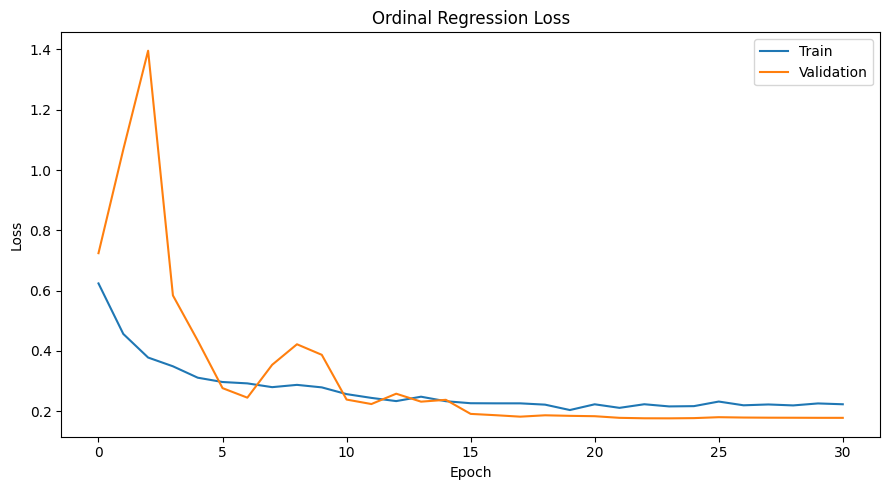

In [19]:
plt.figure(figsize=(9, 5))
plt.plot(history_ord.history["loss"], label="Train")
plt.plot(history_ord.history["val_loss"], label="Validation")
plt.title("Ordinal Regression Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()


## Convert cumulative ordinal probabilities into a class prediction

For four classes, the model outputs three probabilities corresponding to the thresholds.

The predicted class is the number of thresholds whose probability is at least 0.5.


19/19 ━━━━━━━━━━━━━━━━━━━━ 23s 741ms/step
Ordinal Accuracy: 0.7687
Ordinal MAE: 0.2449

Classification Report:
              precision    recall  f1-score   support

      unripe     0.8154    0.8689    0.8413        61
   half-ripe     0.7231    0.6351    0.6763        74
        ripe     0.7347    0.7826    0.7579        92
    overripe     0.8182    0.8060    0.8120        67

    accuracy                         0.7687       294
   macro avg     0.7728    0.7731    0.7719       294
weighted avg     0.7675    0.7687    0.7670       294



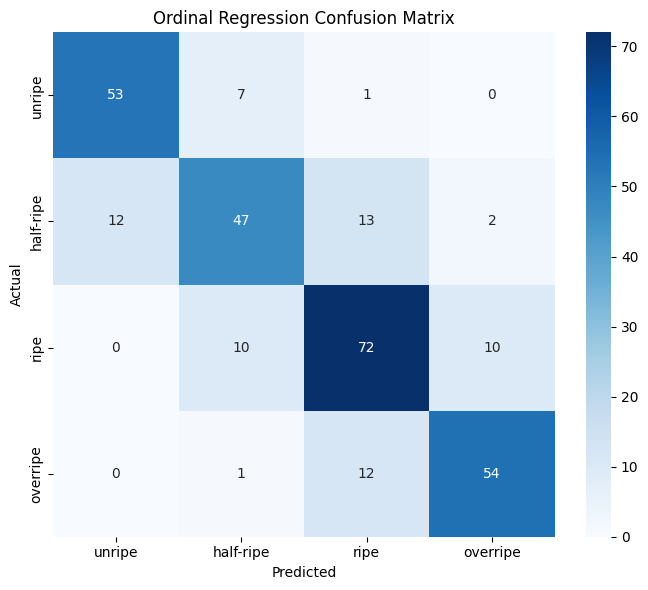

In [20]:
ord_prob = ordinal_model.predict(test_ds_ord)
ord_pred = (ord_prob >= 0.5).sum(axis=1)
ord_true = test_df["label"].values

ord_accuracy = accuracy_score(ord_true, ord_pred)
ord_mae = mean_absolute_error(ord_true, ord_pred)

print(f"Ordinal Accuracy: {ord_accuracy:.4f}")
print(f"Ordinal MAE: {ord_mae:.4f}")

print("\nClassification Report:")
print(classification_report(
    ord_true,
    ord_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

plt.figure(figsize=(7, 6))
sns.heatmap(
    confusion_matrix(ord_true, ord_pred, labels=np.arange(NUM_CLASSES)),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.title("Ordinal Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


# Final comparison

Accuracy measures exact class agreement.

MAE measures the average absolute distance between the true and predicted ripeness level:

- 0 = exact class
- 1 = one ripeness stage away
- 2 = two stages away
- 3 = three stages away

Because ripeness is ordinal, MAE is particularly informative: predicting `Ripe` for `Half-ripe` is a smaller ordinal error than predicting `Overripe` for `Unripe`.


In [21]:
comparison = pd.DataFrame({
    "Model": [
        "ResNet152 Categorical",
        "ResNet152 Ordinal"
    ],
    "Accuracy": [
        cat_accuracy,
        ord_accuracy
    ],
    "MAE": [
        cat_mae,
        ord_mae
    ]
})

display(comparison)

comparison.to_csv(
    MODEL_DIR / "model_comparison.csv",
    index=False
)


,Model,Accuracy,MAE
0,ResNet152 Categorical,0.697279,0.333333
1,ResNet152 Ordinal,0.768707,0.244898


## Error-distance analysis


,Error Distance,Categorical Count,Ordinal Count
0,0,205,226
1,1,80,64
2,2,9,4
3,3,0,0


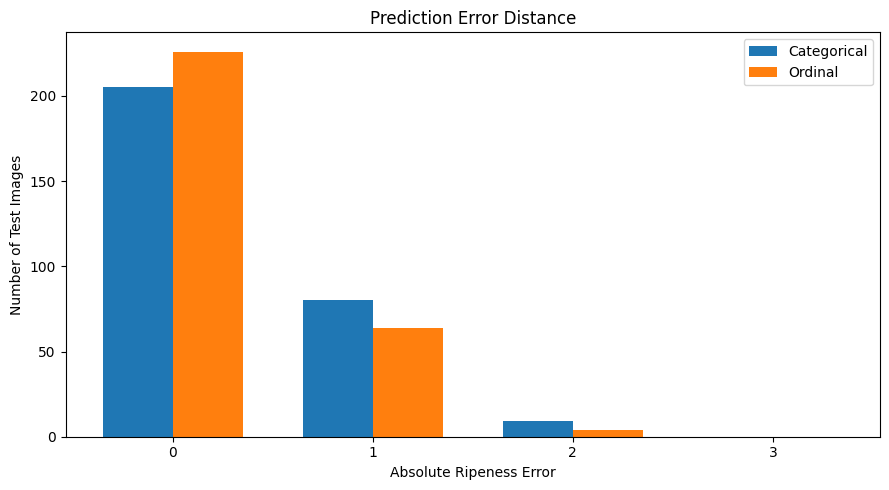

In [22]:
cat_errors = np.abs(cat_true - cat_pred)
ord_errors = np.abs(ord_true - ord_pred)

error_summary = pd.DataFrame({
    "Error Distance": np.arange(NUM_CLASSES),
    "Categorical Count": [
        np.sum(cat_errors == d) for d in range(NUM_CLASSES)
    ],
    "Ordinal Count": [
        np.sum(ord_errors == d) for d in range(NUM_CLASSES)
    ]
})

display(error_summary)

plt.figure(figsize=(9, 5))
x = np.arange(NUM_CLASSES)
width = 0.35

plt.bar(
    x - width/2,
    error_summary["Categorical Count"],
    width,
    label="Categorical"
)

plt.bar(
    x + width/2,
    error_summary["Ordinal Count"],
    width,
    label="Ordinal"
)

plt.xticks(x, [str(i) for i in range(NUM_CLASSES)])
plt.xlabel("Absolute Ripeness Error")
plt.ylabel("Number of Test Images")
plt.title("Prediction Error Distance")
plt.legend()
plt.tight_layout()
plt.show()


Upload a banana image from your device:


Saving image.jpg to image (1).jpg


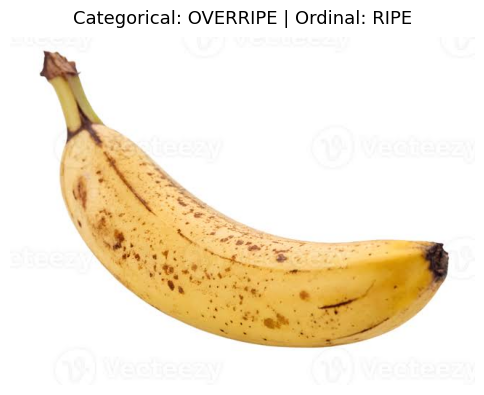

IMAGE: image (1).jpg
--- Categorical Softmax Probabilities ---
  Unripe      :   0.04%
  Half-ripe   :   0.04%
  Ripe        :   0.33%
  Overripe    :  99.59%
  --> Final Prediction: Overripe

--- Ordinal Threshold Probabilities ---
  P(Ripeness > Unripe)     : 1.0000 [✓]
  P(Ripeness > Half-ripe)  : 1.0000 [✓]
  P(Ripeness > Ripe)       : 0.0010 [✗]
  --> Final Prediction: Ripe


In [23]:
from google.colab import files
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow.keras.applications.resnet import preprocess_input

def predict_single_image(image_path):
    # 1. Load and display image
    raw_img = Image.open(image_path).convert('RGB')

    # 2. Preprocess to match training pipeline (224x224, ResNet preprocess_input)
    img_resized = raw_img.resize(IMG_SIZE)
    img_array = np.array(img_resized, dtype=np.float32)
    img_preprocessed = preprocess_input(img_array)
    img_batch = np.expand_dims(img_preprocessed, axis=0)

    # 3. Categorical Model Prediction
    cat_probs = categorical_model.predict(img_batch, verbose=0)[0]
    cat_pred_idx = np.argmax(cat_probs)
    cat_class = CLASS_NAMES[cat_pred_idx]

    # 4. Ordinal Model Prediction
    # Counts thresholds where sigmoid output >= 0.5
    ord_probs = ordinal_model.predict(img_batch, verbose=0)[0]
    ord_pred_idx = int(np.sum(ord_probs >= 0.5))
    ord_class = CLASS_NAMES[ord_pred_idx]

    # 5. Display visualization and outputs
    plt.figure(figsize=(6, 6))
    plt.imshow(raw_img)
    plt.axis("off")
    plt.title(f"Categorical: {cat_class.upper()} | Ordinal: {ord_class.upper()}", fontsize=13, pad=10)
    plt.show()

    print("=" * 45)
    print(f"IMAGE: {image_path}")
    print("=" * 45)
    print("--- Categorical Softmax Probabilities ---")
    for name, p in zip(CLASS_NAMES, cat_probs):
        print(f"  {name.capitalize():<12}: {p * 100:6.2f}%")
    print(f"  --> Final Prediction: {cat_class.capitalize()}\n")

    print("--- Ordinal Threshold Probabilities ---")
    threshold_names = [f"P(Ripeness > {name.capitalize()})" for name in CLASS_NAMES[:-1]]
    for t_name, p in zip(threshold_names, ord_probs):
        passed = "✓" if p >= 0.5 else "✗"
        print(f"  {t_name:<25}: {p:6.4f} [{passed}]")
    print(f"  --> Final Prediction: {ord_class.capitalize()}")
    print("=" * 45)

# Trigger file upload dialog
print("Upload a banana image from your device:")
uploaded = files.upload()

for filename in uploaded.keys():
    predict_single_image(filename)

# Save the final models


In [24]:
categorical_model.save(
    MODEL_DIR / "resnet152_categorical_final.keras"
)

ordinal_model.save(
    MODEL_DIR / "resnet152_ordinal_final.keras"
)

print("Models and comparison results saved in:", MODEL_DIR.resolve())


Models and comparison results saved in: /content/saved_models


# Reproducibility checklist

Before training:

- Put the original BananaID ripeness images under `./dataset`.
- Confirm the four folders/classes are **Unripe, Half-ripe, Ripe, Overripe**.
- Keep the original images only; do not place augmented copies into the dataset used for splitting.
- Confirm that the class distribution printed by the notebook is reasonable.

Experiment settings:

- Model: **ResNet152**
- Weights: **None — trained from scratch**
- Input: **224 × 224 RGB**
- Maximum epochs: **50**
- Batch size: **16**
- Optimizer: **Adam**
- Learning rate: **1e-4**
- Split: **70/15/15**, stratified
- Metrics: **Accuracy and MAE**
- Baseline: **Softmax cross-entropy**
- Proposed approach: **Ordinal cumulative-threshold loss**

## Research note

This notebook is now aligned to a genuine ripeness-classification dataset rather than a generic fruit-recognition dataset. BananaID has four ordered ripeness stages and 1,960 original ripeness images, making it a more direct fit for an ordinal-regression experiment. citeturn0search1
